# 02 · Análise exploratória

**Objetivo:** descrever demanda e faturamento (individual e consolidado), entender o significado de ausentes, zeros e valores extremos, e analisar produtos e preços. Nada é removido automaticamente; cada decisão de tratamento é justificada.

| Seção | Módulo |
|---|---|
| 1. Descritiva | `src/eda/descriptive_analysis.py` |
| 2. Valores ausentes | `src/eda/missing_values.py` |
| 3. Valores zero | `src/eda/zero_analysis.py` |
| 4. Outliers | `src/eda/outlier_analysis.py` |
| 5. Produtos e mix | `src/eda/product_analysis.py` |

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

from src.data.preprocessing import preparar_base
from src.eda import descriptive_analysis as da, missing_values as mv, zero_analysis as za, outlier_analysis as oa, product_analysis as pa
from src.eda import trend_seasonality as ts, duplicate_analysis as du
from src.structural_breaks.structural_break_test import detectar_quebras_nivel

base = preparar_base()
ORIGEM = pd.Timestamp("2025-03-09")   # quebras detectadas só com o treino (notebook 03)
quebras = {s: detectar_quebras_nivel(base.series[(s, "demanda")].loc[:ORIGEM])[0] for s in ("Máquina 1", "Total")}
rotulos = {s: {f"quebra {q:%d/%m/%y}": q for q in qs} for s, qs in quebras.items()}

2026-11-10 19:10:05 | INFO    | src.data.load_data | Dados brutos conferidos com o MANIFEST.json (SHA-256)


2026-11-10 19:10:05 | INFO    | src.data.load_data | index_1.csv: 3636 registros válidos (máquina 1)


2026-11-10 19:10:05 | INFO    | src.data.load_data | index_2.csv: 262 registros válidos (máquina 2)


2026-11-10 19:10:05 | INFO    | src.data.preprocessing | Séries diárias construídas: {('Máquina 1', 'demanda'): 388, ('Máquina 1', 'receita'): 388, ('Máquina 2', 'demanda'): 44, ('Máquina 2', 'receita'): 44, ('Total', 'demanda'): 388, ('Total', 'receita'): 388}


## 1. Análise descritiva

### 1.1 Distribuição das vendas e do faturamento

,série,alvo,início,dias,total,média,mediana,desvio-padrão,CV,mínimo,p5,p95,máximo,assimetria,var/média,ticket médio
0,Máquina 1,demanda,01/03/2024,388,"3,636.000",9.370,9.000,5.210,0.560,0.000,2.000,19.650,26.000,0.700,2.900,31.750
1,Máquina 1,receita,01/03/2024,388,"115,431.580",297.500,272.840,163.430,0.550,0.000,63.090,598.890,836.660,0.640,NaN,31.750
2,Máquina 2,demanda,08/02/2025,44,262.000,5.950,5.000,3.830,0.640,0.000,0.150,11.000,17.000,0.830,2.470,26.300
3,Máquina 2,receita,08/02/2025,44,"6,890.000",156.590,135.000,99.860,0.640,0.000,4.050,305.100,444.000,0.760,NaN,26.300
4,Total,demanda,01/03/2024,388,"3,898.000",10.050,9.000,6.220,0.620,0.000,2.000,24.000,35.000,1.100,3.850,31.380
5,Total,receita,01/03/2024,388,"122,321.580",315.260,279.200,187.710,0.600,0.000,63.090,702.190,979.080,0.930,NaN,31.380


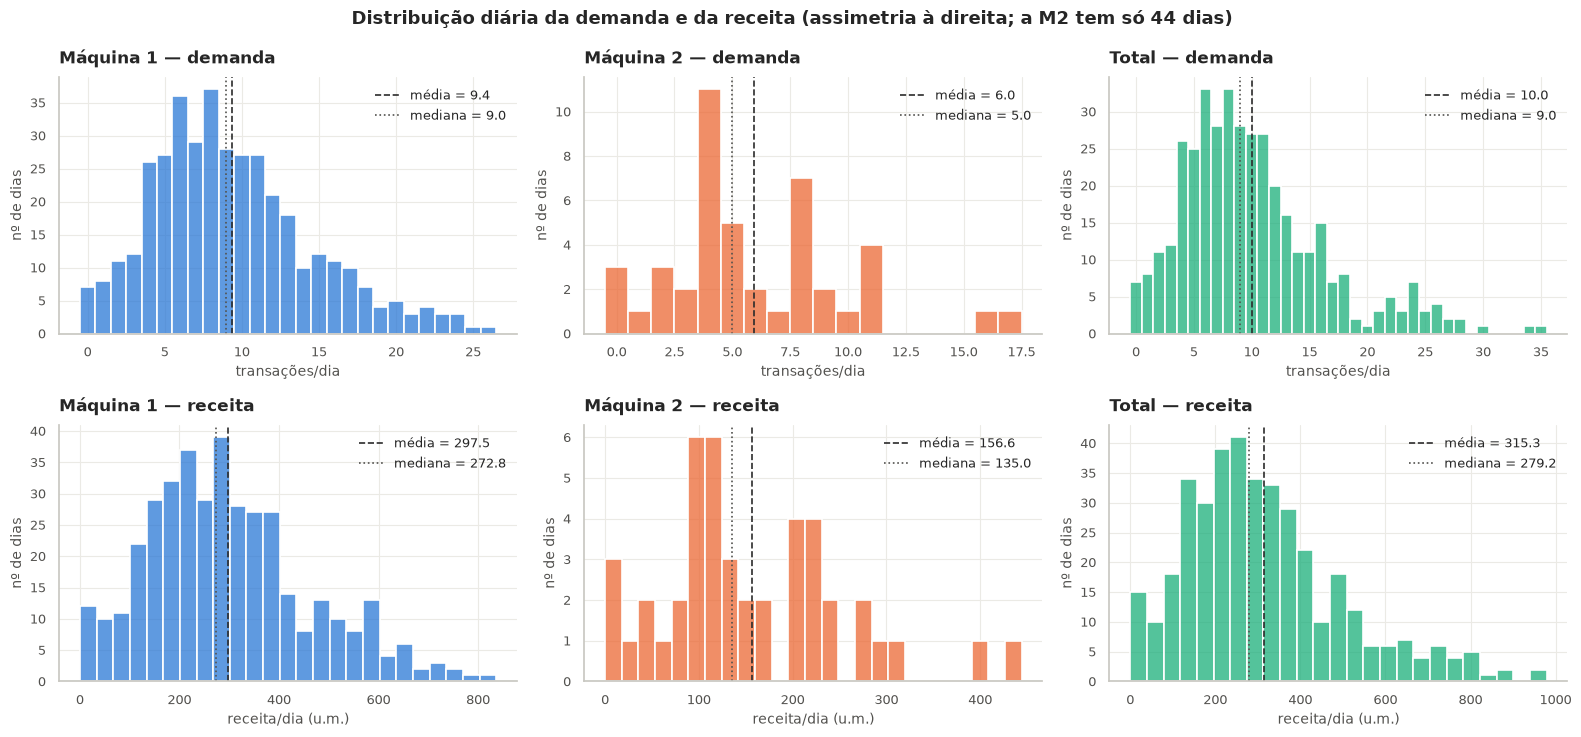

In [2]:
display(da.resumo_series(base).round(2))
mostrar(da.grafico_distribuicoes(base))

**Leitura:** as distribuições diárias são **assimétricas à direita** (média > mediana) e discretas na demanda: há muitos dias com 5–12 vendas e uma cauda de dias com 20–35. Isso já sugere modelos de contagem ou transformações estabilizadoras de variância, em vez de supor normalidade. A receita acompanha a demanda, porque o ticket médio é estável dentro de cada tabela de preços.

### 1.2 Evolução temporal e comparação mensal

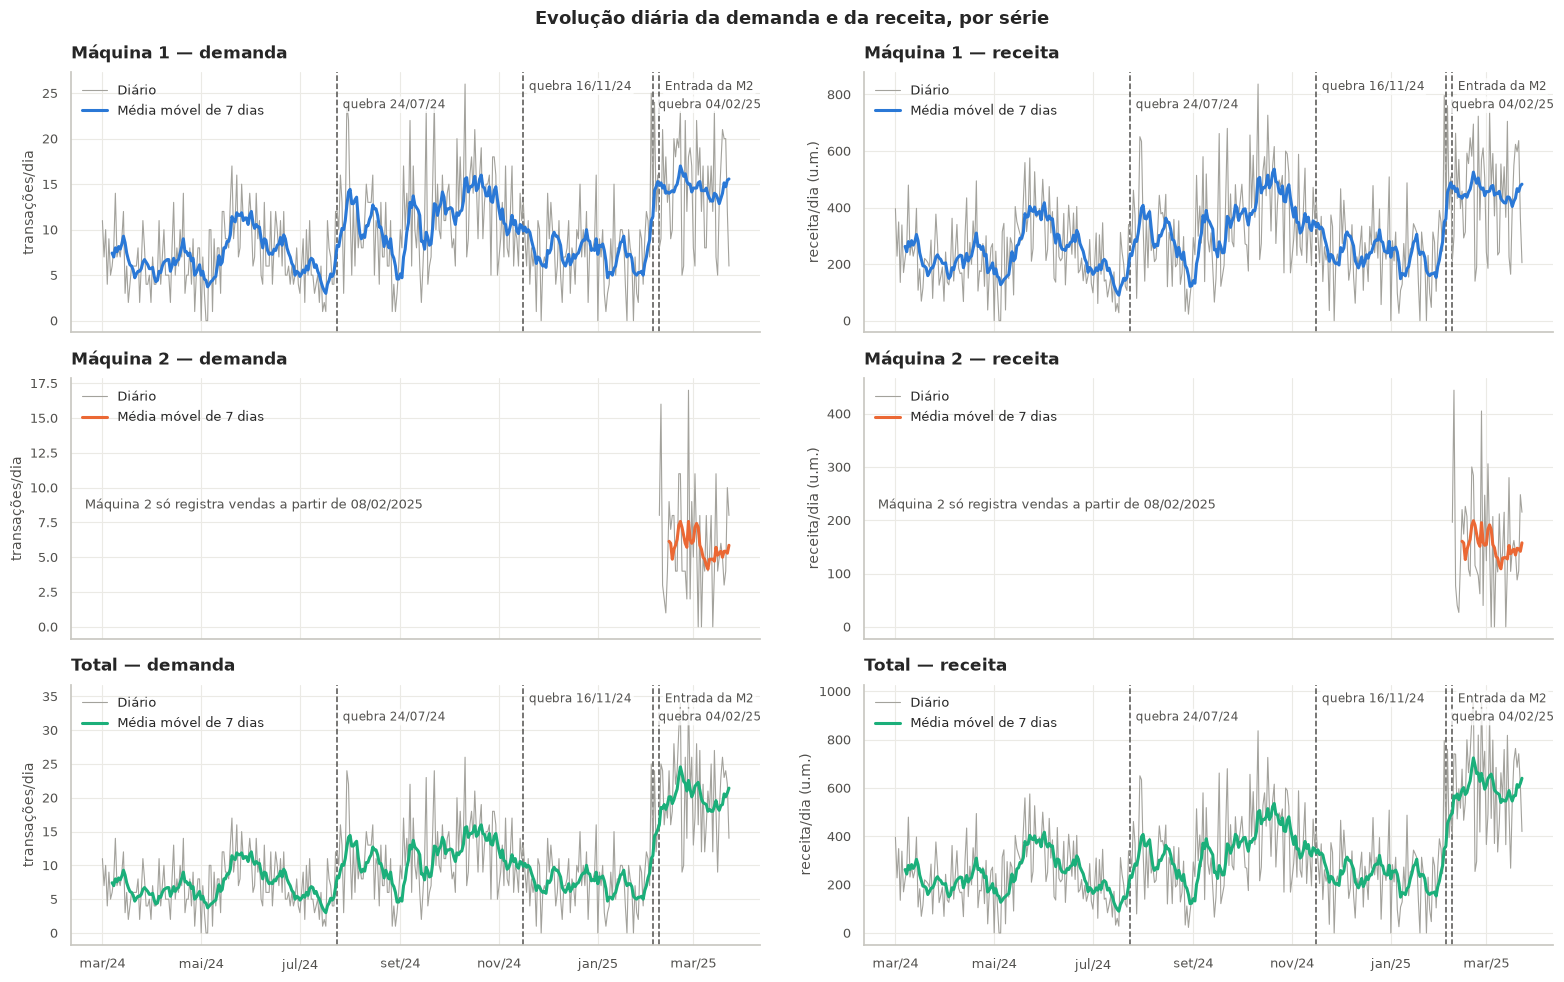

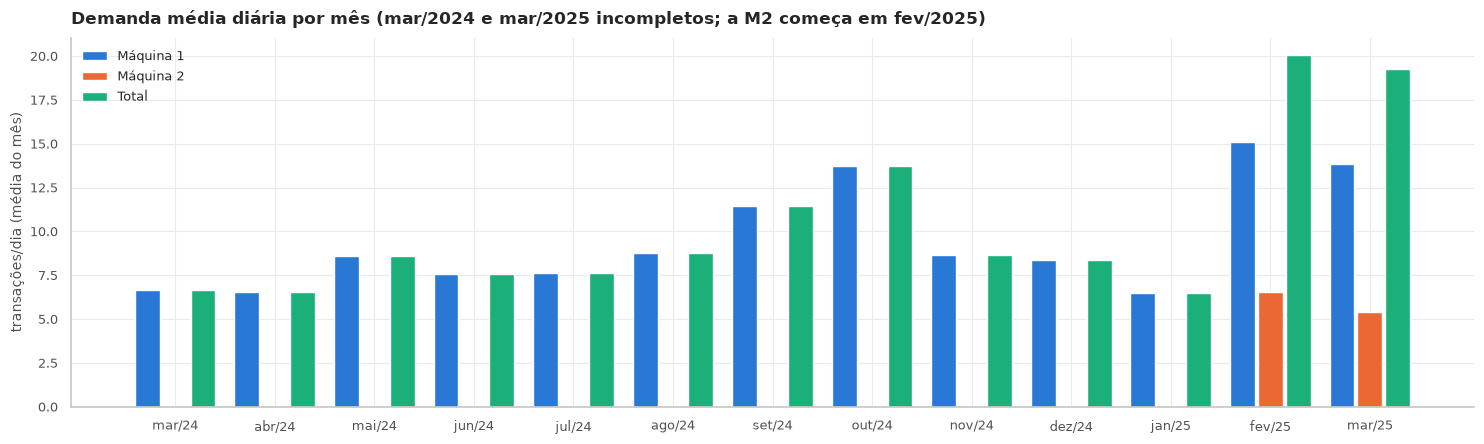

In [3]:
mostrar(da.grafico_evolucao(base, rotulos['Total']))
mostrar(da.grafico_mensal(base))

**Leitura:** a série da M1 passa por **patamares** bem definidos, e não por uma tendência suave:
- baixo até mai/2024;
- alta em ago–out/2024;
- queda em nov/2024–jan/2025;
- salto em fev/2025.

Esses patamares são as quebras testadas formalmente no notebook 03. Com apenas um ano de dados, **não é possível estimar sazonalidade anual**: um mês alto pode ser sazonal ou um regime.

### 1.3 Horário e dia da semana

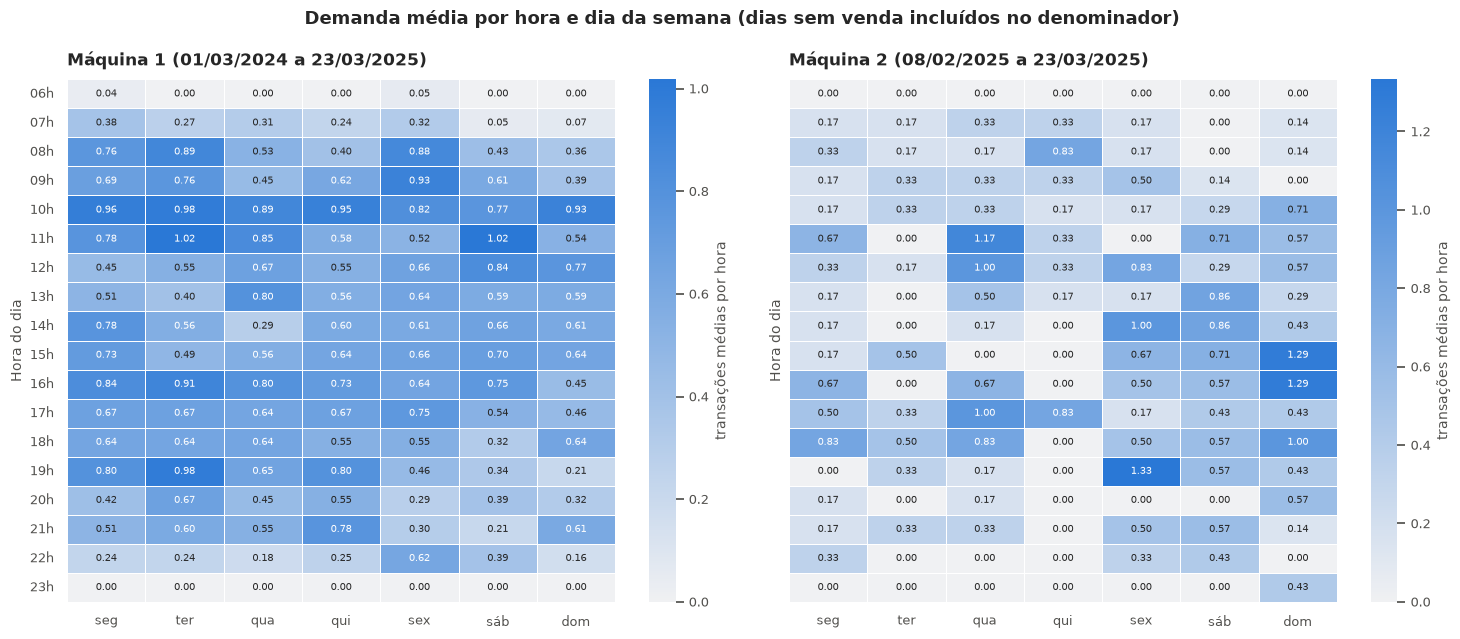

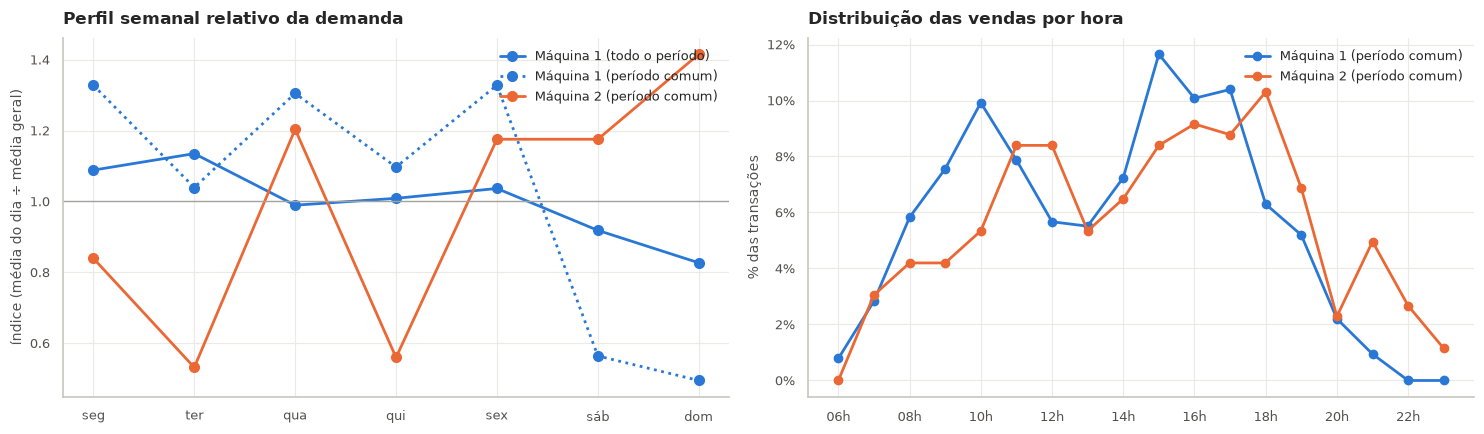

,dias,demanda média,CV demanda,receita média,ticket médio,% demanda no fim de semana,dias sem venda
série,,,,,,,
Máquina 1,44,14.430,0.390,449.710,31.160,16.850,0
Máquina 2,44,5.950,0.640,156.590,26.300,41.220,3


Mann-Whitney (nível M1 × M2): p = 2.08e-10 | Spearman diário M1 × M2: ρ = -0.11 (p = 0.48)


In [4]:
mostrar(da.grafico_hora_dia(base))
mostrar(da.grafico_perfis(base))
comp = da.comparar_periodo_comum(base)
display(comp.round(2))
print(f"Mann-Whitney (nível M1 × M2): p = {comp.attrs['mann_whitney_p']:.2e} | Spearman diário M1 × M2: ρ = {comp.attrs['spearman'][0]:.2f} (p = {comp.attrs['spearman'][1]:.2f})")

**Leitura:**
- **A demanda por hora é baixa em todo o dia** (em média, menos de 1 venda por hora na M1). Nenhuma hora vende na maioria dos dias. Por isso a modelagem é **diária**: uma previsão horária seria dominada por ruído de contagem.
- **Os perfis das máquinas são opostos.**
  - A M1 é mais forte em dias úteis: 17% da demanda no fim de semana.
  - A M2 concentra **41%** no fim de semana e vende mais à noite.
  - No período comum, a M1 vende 14,4/dia e a M2, 6,0/dia (p < 0,001); as vendas diárias não são correlacionadas.
- **Consequência:** cada máquina precisa de parâmetros próprios, e o padrão semanal deve ser estimado por série.

#### Padrão semanal da M1 antes e depois de 2025

O perfil por dia da semana é calculado **descontando o nível de cada regime**, para que um salto de patamar não se confunda com padrão semanal. O teste F das 6 dummies de dia da semana inclui efeitos fixos de regime. O teste formal por regime está no notebook 05.

,seg,ter,qua,qui,sex,sáb,dom
antes de 30/01/2025,1.900,16.400,-10.500,0.700,-2.700,2.000,-7.700
desde 30/01/2025,38.900,1.200,35.900,0.700,24.200,-41.000,-50.500


,período,dias,F (dia da semana | regime),p,R² parcial do dia da semana,fim de semana vs dias úteis (%)
0,antes de 30/01/2025,335,1.760,0.107,0.031,-3.991
1,desde 30/01/2025,53,25.749,0.000,0.771,-54.692


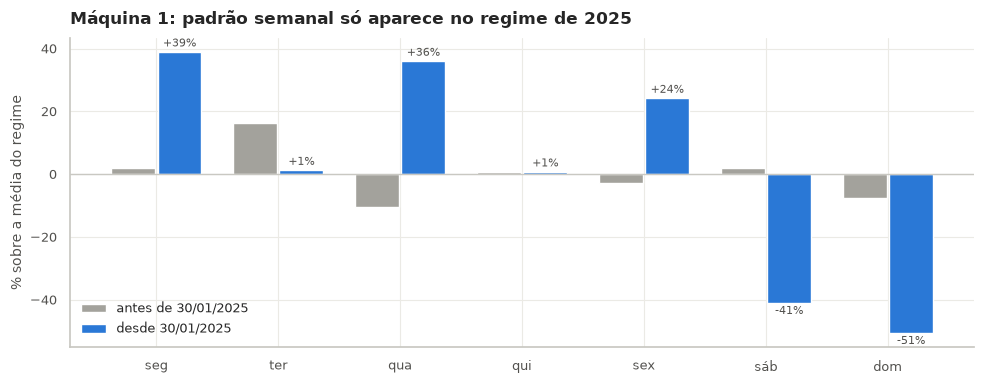

In [5]:
perfil_sem, teste_sem = ts.perfil_semanal_antes_depois(base.series[("Máquina 1", "demanda")], quebras["Máquina 1"], quebras["Máquina 1"][-1])
display(perfil_sem.round(1))
display(teste_sem.round(4))
mostrar(ts.grafico_perfil_antes_depois(perfil_sem, "Máquina 1"))

**Leitura:**
- **Antes de 30/01/2025 a M1 não tem padrão semanal.** Os dias da semana explicam ~3% da variação dentro dos regimes (p ≈ 0,11), e o fim de semana vende só ~4% menos que os dias úteis.
- **Desde 30/01/2025 o padrão é forte:** R² ≈ 0,77 (p < 0,001), com o fim de semana **~55% abaixo** dos dias úteis.
- Segunda, quarta e sexta vendem 24% a 39% acima da média, e terça e quinta ficam na média. É um padrão de **agenda fixa**, compatível com o novo público (aulas, turnos ou expediente), mas a base não permite confirmar a causa.
- **Consequência para a operação:** o abastecimento da M1 em 2025 deve ser planejado por dia da semana. Para a modelagem, o padrão semanal precisa ser reestimado no regime vigente: janelas curtas, como o Holt-Winters de 8 semanas.

## 2. Valores ausentes

Há três tipos de ausência, cada um com significado e tratamento próprios (detalhes no docstring de `missing_values.py`).

,arquivo,coluna,registros,nulos,% nulos,tipo
0,index_1.csv,date,3636,0,0.000,sem ausência
1,index_1.csv,datetime,3636,0,0.000,sem ausência
2,index_1.csv,cash_type,3636,0,0.000,sem ausência
3,index_1.csv,card,3636,89,2.448,valor ausente
4,index_1.csv,money,3636,0,0.000,sem ausência
5,index_1.csv,coffee_name,3636,0,0.000,sem ausência
6,index_2.csv,date,262,0,0.000,sem ausência
7,index_2.csv,datetime,262,0,0.000,sem ausência
8,index_2.csv,cash_type,262,0,0.000,sem ausência
9,index_2.csv,card,262,262,100.000,coluna inexistente no arquivo


card,card nulo,card preenchido
cash_type,,
card,0,3547
cash,89,0


,dias no calendário global,fora do período ativo (máquina inexistente),dias com venda,dias com zero vendas
série,,,,
Máquina 1,388,0,381,7
Máquina 2,388,344,41,3
Total,388,0,381,7


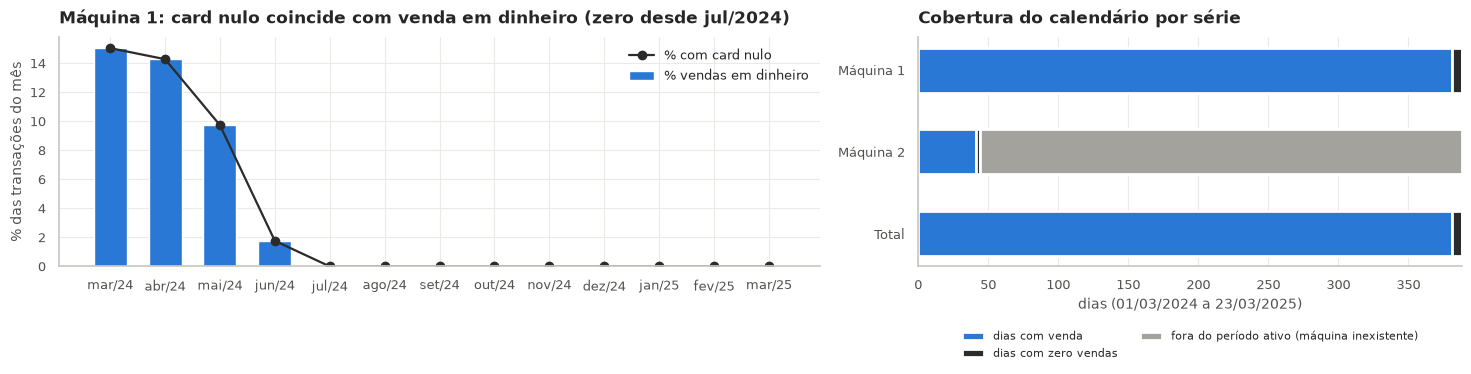

In [6]:
display(mv.tabela_ausentes(base))
display(mv.padrao_card_pagamento(base))
display(mv.cobertura_calendario(base))
mostrar(mv.grafico_ausentes(base))

**Leitura e decisão:**
- **`card` nulo (89 vendas, 2,4% da M1)** ocorre **exatamente** nas vendas em dinheiro: 89 de 89. Não é falha de coleta; é estrutural, porque a venda em dinheiro não tem cartão.
  - Desde jul/2024 a M1 não registra dinheiro, então a identificação de clientes é **completa** no período da quebra de 2025.
  - Tratamento: nenhum (não se imputa um identificador). As análises de clientes usam só vendas com cartão e declaram essa limitação.
- **`card` inexistente na M2 (100%)**: é ausência de coluna. A análise de novos clientes fica restrita à M1.
- **M2 antes de 08/02/2025 (344 dias)**: a máquina não existe nesse período. Não é demanda zero nem dado a imputar.
- **`datetime` e `money` não têm nenhum ausente**, então a previsão não é afetada.

## 3. Valores zero: ausência de vendas ou situação operacional?

,dias,dias com zero vendas,% de dias zerados,maior sequência de zeros,receita zero ⇔ demanda zero
série,,,,,
Máquina 1,388,7,1.804,2,True
Máquina 2,44,3,6.818,1,True
Total,388,7,1.804,2,True


,série,data,dia da semana,data especial,dias zerados consecutivos,"λ local (mesmo dia da semana, ±4 sem.)",P(Y = 0 | λ),leitura
0,Máquina 1,2024-05-01,qua,Dia do Trabalho,1,7.250,0.001,implausível como acaso → provável fechamento/f...
1,Máquina 1,2024-05-04,sáb,—,2,7.750,0.000,implausível como acaso → provável fechamento/f...
2,Máquina 1,2024-05-05,dom,—,2,8.750,0.000,implausível como acaso → provável fechamento/f...
3,Máquina 1,2024-11-27,qua,—,1,8.375,0.000,implausível como acaso → provável fechamento/f...
4,Máquina 1,2025-01-01,qua,Ano Novo,1,7.250,0.001,implausível como acaso → provável fechamento/f...
5,Máquina 1,2025-01-19,dom,—,1,6.375,0.002,implausível como acaso → provável fechamento/f...
6,Máquina 1,2025-01-23,qui,—,1,10.375,0.000,implausível como acaso → provável fechamento/f...
7,Máquina 2,2025-03-04,ter,—,1,3.800,0.022,compatível com demanda baixa
8,Máquina 2,2025-03-06,qui,—,1,4.000,0.018,compatível com demanda baixa
9,Máquina 2,2025-03-13,qui,—,1,4.000,0.018,compatível com demanda baixa


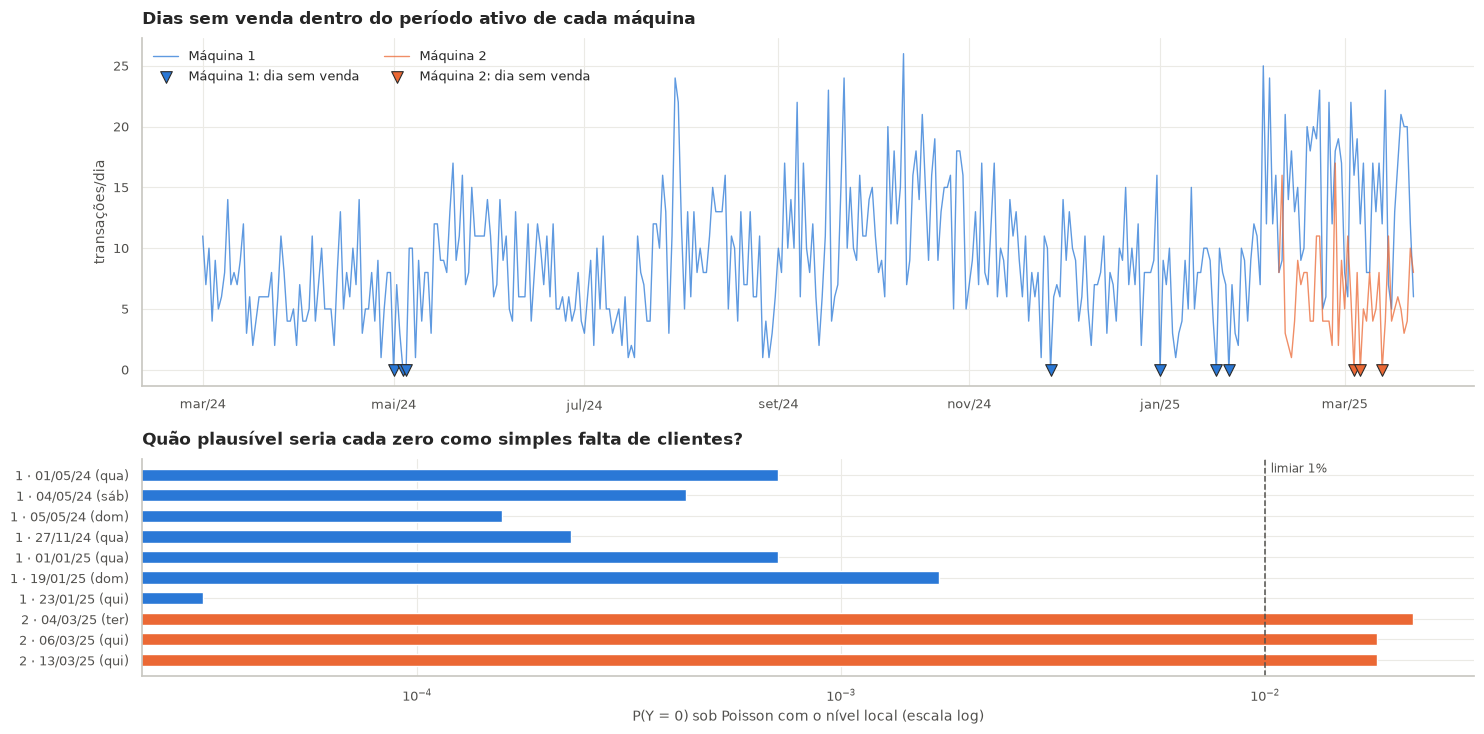

In [7]:
display(za.resumo_zeros(base))
display(za.tabela_zeros(base).round(4))
mostrar(za.grafico_zeros(base))

**Leitura:**
- São **7 dias zerados na M1** (1,8%) e **3 na M2**, isolados: no máximo 2 consecutivos (04–05/05/2024).
- **Na M1, todos os zeros são implausíveis como simples falta de clientes.** Com a demanda local do mesmo dia da semana, P(Y = 0) fica entre 0,00003 e 0,002. Dois deles caem em feriados (01/05 e 01/01).
  - A leitura mais provável é **fechamento ou indisponibilidade da máquina**, e não demanda zero "natural".
  - Os dados não têm um registro de funcionamento que permita confirmar isso.
- **Na M2, os 3 zeros são compatíveis com demanda baixa** (P(Y = 0) ≈ 2%): o nível da M2 é de ~4 vendas nesses dias da semana.

**Decisão: manter os zeros como zero.**
1. Zero transações implica receita zero.
2. Imputar uma "demanda que existiria" inventaria vendas que não aconteceram.
3. São 7 de 388 dias, sem efeito material nas estimativas.
4. Em produção, um zero fora do intervalo de previsão é exatamente o tipo de anomalia operacional que o monitoramento deve sinalizar (docs/architecture.md).

## 4. Outliers: identificação, causas e impacto

,série,alvo,IQR,MAD,z-score,condicional (dia da semana),resíduo STL,atípico
0,Máquina 1,demanda,12,2,1,4,25,2
1,Máquina 1,receita,8,1,2,2,24,1
2,Máquina 2,demanda,2,0,0,1,8,1
3,Máquina 2,receita,2,0,0,0,5,0
4,Total,demanda,21,14,3,7,23,7
5,Total,receita,19,4,4,4,31,5


,série,alvo,data,valor,nível local (tendência STL),desvio vs nível (%),nº de critérios,transações no dia,registros repetidos,causa provável
0,Máquina 1,demanda,2024-10-11,26.000,12.600,107.000,4,26,0,"evento legítimo (pico/vale isolado, transações..."
1,Máquina 1,demanda,2025-02-03,25.000,12.000,107.900,3,25,0,até 14 dias de uma quebra de nível (30/01/2025)
0,Máquina 1,receita,2024-10-11,836.700,402.400,107.900,4,26,0,"evento legítimo (pico/vale isolado, transações..."
0,Máquina 2,demanda,2025-02-26,17.000,5.700,199.800,3,17,1,"evento legítimo (pico/vale isolado, transações..."
0,Total,demanda,2024-10-11,26.000,12.600,105.900,3,26,0,"evento legítimo (pico/vale isolado, transações..."
1,Total,demanda,2024-12-26,2.000,8.700,-77.000,2,2,0,"evento legítimo (pico/vale isolado, transações..."
2,Total,demanda,2025-02-03,25.000,12.300,102.500,3,25,0,até 14 dias de uma quebra de nível (04/02/2025)
3,Total,demanda,2025-02-09,25.000,16.300,53.400,3,25,0,até 14 dias de uma quebra de nível (04/02/2025)
4,Total,demanda,2025-02-20,30.000,19.300,55.600,4,30,0,"evento legítimo (pico/vale isolado, transações..."
5,Total,demanda,2025-02-21,34.000,18.800,81.300,4,34,0,"evento legítimo (pico/vale isolado, transações..."


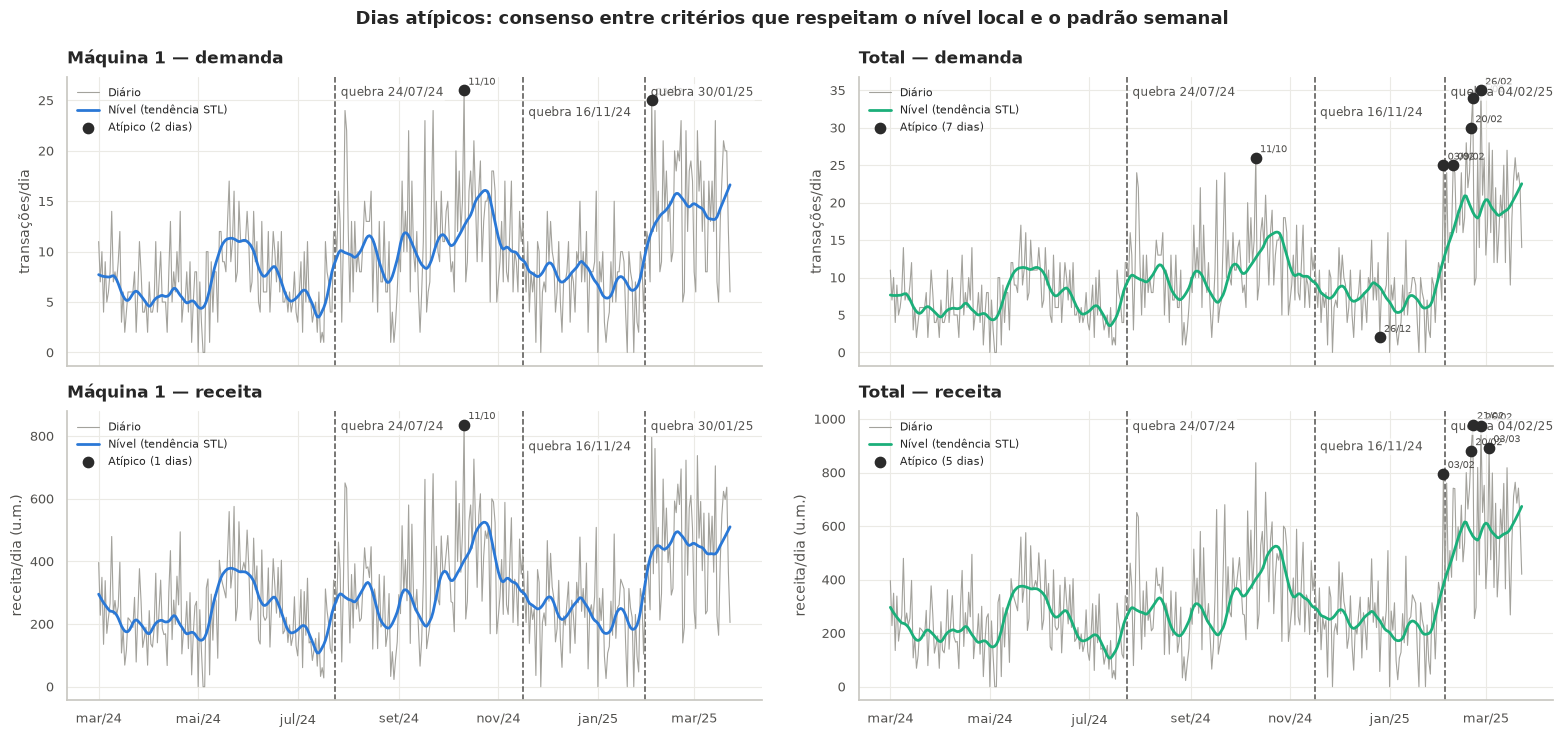

In [8]:
display(oa.resumo_criterios(base, quebras))
atipicos = pd.concat([oa.investigar(base, s, a, quebras.get(s)) for s in ("Máquina 1", "Máquina 2", "Total") for a in ("demanda", "receita")])
display(atipicos.round(1))
mostrar(oa.grafico_outliers(base, rotulos))

**Leitura:**
- **Os critérios discordam muito.**
  - O IQR marca 12 a 21 dias, porque ignora os patamares: dias normais de um regime alto viram "outliers".
  - O resíduo da STL marca mais de 20, porque os resíduos têm cauda pesada.
  - O z-score marca quase nada.
  - Só o **consenso de critérios que respeitam nível e padrão semanal** é informativo: 2 dias na demanda da M1 e 7 no Total.
- **Causas investigadas:**
  - **11/10/2024** (26 vendas, o dobro do nível local): as transações são consistentes (preços da tabela vigente, nenhum registro repetido). É um **pico legítimo**.
  - **03/02/2025**: fica a 4 dias da quebra de 30/01. É o próprio **salto de nível**, não uma anomalia.
  - Os dias do Total em fev–mar/2025 são dias altos legítimos: soma de M1 e M2 depois da entrada da segunda máquina.
  - **Nenhuma inconsistência de registro foi encontrada.**

In [9]:
sens = oa.sensibilidade_modelagem(base)
display(sens.round(3))
print('Diferença média de MAE (winsorizado − bruto):', round(sens.iloc[:, 2].mean(), 4))

histórico,bruto,winsorizado (atípicos → p1/p99),diferença (winsorizado − bruto)
origem,,,
2024-10-20,4.744,4.647,-0.097
2024-11-03,4.726,4.682,-0.044
2024-11-17,4.976,4.976,0.000
2024-12-01,3.286,3.286,0.000
2024-12-15,2.446,2.446,0.000
2024-12-29,3.417,3.417,0.000
2025-01-12,3.446,3.446,0.000
2025-01-26,5.881,5.881,0.000
2025-02-09,5.988,6.030,0.042


Diferença média de MAE (winsorizado − bruto): -0.0053


**Impacto na modelagem:**
- A Média 4 semanas foi prevista em 11 origens com o histórico bruto e com os atípicos winsorizados.
- A diferença média de MAE é **≈ 0**: os poucos atípicos não distorcem o nível.

**Decisão:** **nenhum valor é removido ou alterado.** Os picos legítimos fazem parte da variabilidade que os **intervalos de previsão** precisam cobrir. As mudanças de nível são tratadas como **quebras estruturais** (dummies e janelas de estimação), e não como outliers.

### 4.1 Em que dias caem as anomalias?

Quedas (dias sem venda da M1 e vales atípicos) e picos são separados, porque podem ter causas diferentes. A proporção em feriado ou fim de semana é comparada com a do calendário (2 de cada 7 dias já são fim de semana) por um teste binomial unilateral.

In [10]:
cal_anom, cal_resumo = oa.calendario_anomalias(base, quebras)
display(cal_anom)
display(cal_resumo.round(4))

,data,sentido,séries,dia da semana,calendário,feriado ou fim de semana
0,2024-05-01,queda,Máquina 1 (zero vendas),qua,feriado,True
1,2024-05-04,queda,Máquina 1 (zero vendas),sáb,fim de semana,True
2,2024-05-05,queda,Máquina 1 (zero vendas),dom,fim de semana,True
3,2024-10-11,pico,"Máquina 1 (demanda), Máquina 1 (receita), Tota...",sex,dia útil,False
4,2024-11-27,queda,Máquina 1 (zero vendas),qua,dia útil,False
5,2024-12-26,queda,Total (demanda),qui,dia seguinte a feriado,True
6,2025-01-01,queda,Máquina 1 (zero vendas),qua,feriado,True
7,2025-01-19,queda,Máquina 1 (zero vendas),dom,fim de semana,True
8,2025-01-23,queda,Máquina 1 (zero vendas),qui,dia útil,False
9,2025-02-03,pico,"Máquina 1 (demanda), Total (demanda), Total (r...",seg,dia útil,False


,sentido,dias,em feriado ou fim de semana,%,% esperado pelo calendário,"p (binomial, unilateral)"
0,pico,7,1,14.286,30.412,0.921
1,queda,8,6,75.000,30.412,0.012


**Leitura:**
- **As quedas caem, em sua maioria, em feriados ou fins de semana:** 6 de 8 (75%), contra 30% esperados pelo calendário (p ≈ 0,01).
  - Feriados: 01/05/2024 (Dia do Trabalho) e 01/01/2025 (Ano Novo).
  - Fins de semana: 04–05/05/2024 e 19/01/2025.
  - Dia seguinte ao Natal: 26/12/2024.
  - Só 27/11/2024 e 23/01/2025 são dias úteis sem explicação de calendário.
  - Leitura operacional: o ponto de venda **fecha ou fica sem público em feriados e em alguns fins de semana**. Em produção, um calendário de feriados e de fechamentos evita tratar esses dias como queda de demanda.
- **Os picos são o contrário:** 6 de 7 são dias úteis, concentrados em fev/2025, na chegada da nova clientela da M1 e da M2. Não são efeito de calendário; refletem a mudança de patamar.
- A lista de feriados é genérica (o país não é informado). Com o calendário local, a classificação ficaria mais precisa.

## 5. Registros duplicados: erro de registro ou compra de duas unidades?

A base não tem número de pedido nem log de entrega, então um registro repetido pode ser a mesma venda gravada duas vezes ou duas unidades compradas juntas. Três verificações separam as hipóteses (detalhes no docstring de `duplicate_analysis.py`):
1. **duplicatas exatas** (mesmo horário, produto, valor e pagamento);
2. **registros no mesmo segundo**: se o mesmo segundo também junta produtos diferentes, é um pedido com vários itens;
3. **recompras rápidas na M1**: um registro em dobro ficaria a ~0 s do original. Uma segunda compra real leva o tempo de uma nova preparação. O controle são as recompras de **produto diferente** pelo mesmo cartão, que não podem ser duplicata.

,vendas,duplicatas exatas (registros a mais),% das vendas,grupos no mesmo segundo,registros nesses grupos,grupos com produtos diferentes,duplicatas exatas dentro desses grupos
série,,,,,,,
Máquina 1,3636,0,0.000,0,0,0,0
Máquina 2,262,2,0.760,7,15,5,2


,serie,segundo,itens,produtos,só produtos iguais,pagamento
0,Máquina 2,2025-02-09 18:01:22,3,Tea + Americano with milk + Latte,False,card
1,Máquina 2,2025-02-16 16:41:18,2,Double vanilla + Irish whiskey,False,cash
2,Máquina 2,2025-02-20 09:36:06,2,Espresso + Americano with milk,False,cash
3,Máquina 2,2025-02-22 18:38:38,2,Latte + Americano with milk,False,card
4,Máquina 2,2025-02-26 09:41:12,2,Americano with milk + Americano with milk,True,cash
5,Máquina 2,2025-03-02 12:48:05,2,Cappuccino + Coffee with chocolate,False,cash
6,Máquina 2,2025-03-23 10:25:48,2,Americano with milk + Americano with milk,True,cash


,valor
janela (s),300.000
vendas da M1,"3,636.000"
recompras do mesmo produto,316.000
% das vendas da M1,8.691
recompras de produto diferente,313.000
"intervalo mínimo, mesmo produto (s)",37.992
"intervalo mediano, mesmo produto (s)",62.715
"intervalo mínimo, produto diferente (s)",40.316
"intervalo mediano, produto diferente (s)",65.224
intervalo mínimo entre clientes diferentes (s),41.983


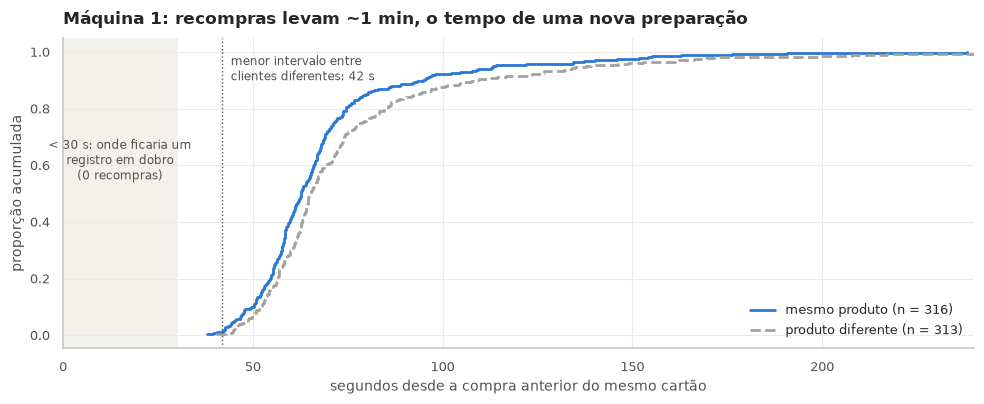

In [11]:
display(du.resumo_duplicados(base).round(2))
display(du.pedidos_mesmo_segundo(base))
recompras, resumo_recompras = du.recompras_rapidas(base)
display(pd.Series(resumo_recompras).round(3).to_frame("valor"))
mostrar(du.grafico_recompras(base))

**Leitura:**
- **Máquina 2: 2 duplicatas exatas** (26/02 09:41:12 e 23/03 10:25:48, dois Americano with milk em dinheiro), 0,8% das vendas.
  - As duas estão entre os **7 grupos de registros no mesmo segundo**, e 5 desses grupos juntam produtos diferentes (por exemplo, Tea + Americano with milk + Latte). É o padrão de um caixa/PDV que lança todos os itens do pedido juntos.
  - A leitura mais provável é **duas unidades na mesma compra**.
- **Máquina 1: nenhuma duplicata exata** (o horário tem milissegundos). Há 316 recompras do mesmo produto pelo mesmo cartão em até 5 min (8,7% das vendas).
  - **Nenhuma ocorre a menos de 30 s**: o intervalo mínimo é 38 s e o mediano, 63 s. É o tempo de uma nova preparação, não de um registro em dobro.
  - As recompras de produto diferente, que não podem ser duplicata, têm distribuição muito parecida (mínimo 40 s, mediana 65 s). O KS detecta uma diferença pequena (p ≈ 0,008): o mesmo produto sai um pouco mais rápido, o que é plausível porque não há escolha de cardápio.
- **Conclusão: não dá para afirmar nada com certeza.** Sem ID de pedido, nenhuma das duas hipóteses pode ser provada. Mas todas as evidências apontam para **compra de duas unidades**, não para erro de registro.
- **Decisão:** nada é removido.
  - Na M2, o impacto seria de 2 vendas em 262.
  - Na M1, remover as recompras subestimaria a demanda em ~9% se elas forem compras reais, como as evidências indicam.
  - Em produção, um ID de pedido no log resolve a dúvida.

## 6. Produtos, mix e preços

,produtos,HHI da receita,HHI equivalente a N produtos iguais,% receita dos 3 maiores
série,,,,
Máquina 1,8,"1,659.100",6.000,61.700
Máquina 2,30,728.800,13.700,35.100
Total,33,"1,566.900",6.400,60.100


,transacoes,receita,preco_medio,precos_distintos,% transações,% receita
produto,,,,,,
Latte,782,"27,866.300",35.600,6,21.500,24.100
Americano with milk,824,"25,269.100",30.700,6,22.700,21.900
Cappuccino,501,"18,034.100",36.000,6,13.800,15.600
Americano,578,"15,062.300",26.100,6,15.900,13.000
Hot chocolate,282,"10,172.500",36.100,6,7.800,8.800
Cocoa,243,"8,678.200",35.700,6,6.700,7.500
Cortado,292,"7,534.900",25.800,5,8.000,6.500
Espresso,134,"2,814.300",21.000,5,3.700,2.400


,produto,data,preço anterior,preço novo,variação %
0,Latte,2024-04-20,38.700,37.720,-2.530
1,Cappuccino,2024-04-20,38.700,37.720,-2.530
2,Americano,2024-04-21,28.900,27.920,-3.390
3,Americano with milk,2024-04-22,33.800,32.820,-2.900
4,Hot chocolate,2024-04-26,38.700,37.720,-2.530
5,Cortado,2024-04-26,28.900,27.920,-3.390
6,Cocoa,2024-04-26,38.700,37.720,-2.530
7,Espresso,2024-05-15,24.000,23.020,-4.080
8,Americano with milk,2024-07-06,32.820,27.920,-14.930
9,Latte,2024-07-06,37.720,32.820,-12.990


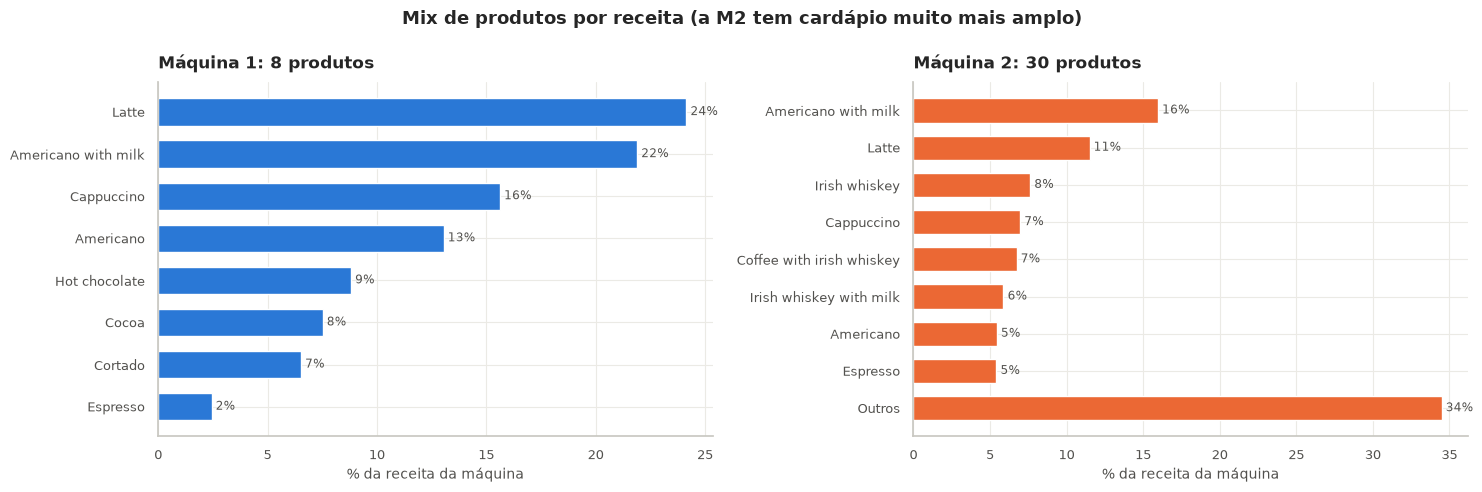

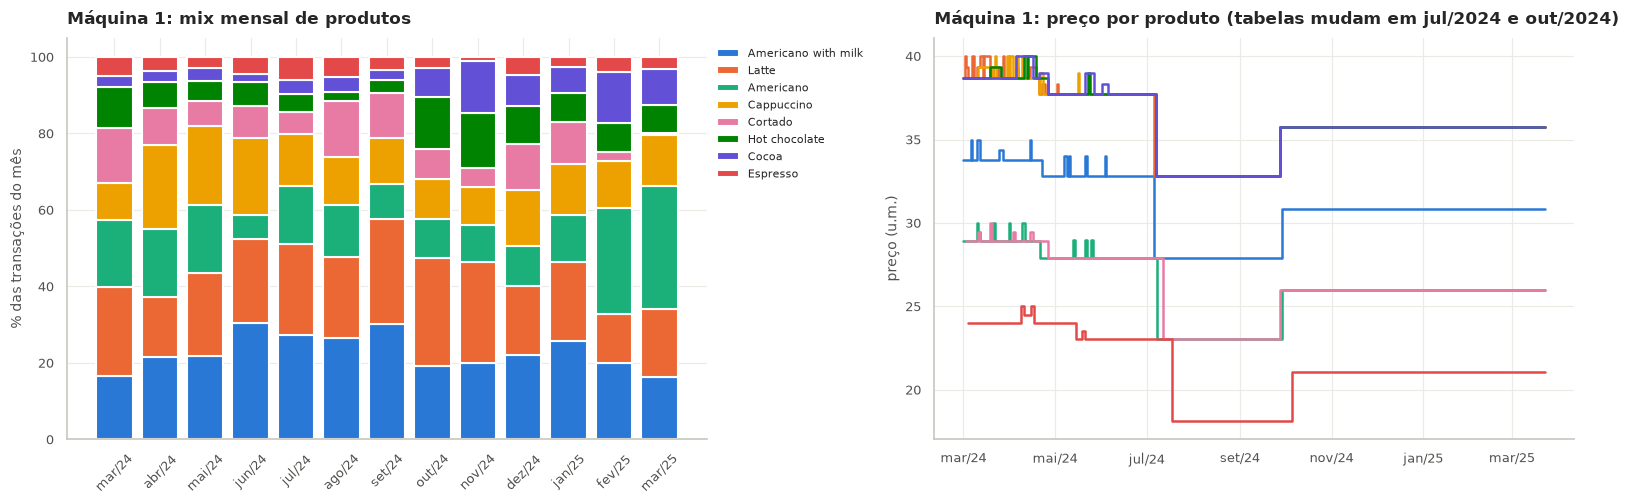

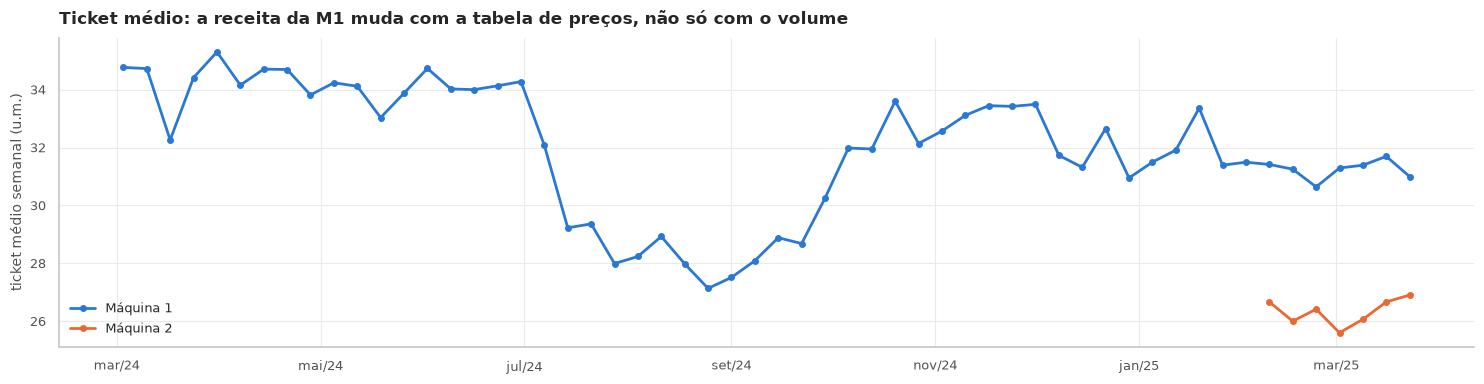

In [12]:
display(pa.concentracao(base).round(1))
display(pa.mix_produtos(base, "Máquina 1").round(1))
display(pa.mudancas_preco(base).round(2))
mostrar(pa.grafico_mix(base))
mostrar(pa.grafico_evolucao_mix(base))
mostrar(pa.grafico_ticket(base))

**Leitura:**
- **A M1 tem um cardápio enxuto:** 8 produtos, com os 3 maiores somando 62% da receita (HHI = 1.659, equivalente a 6 produtos iguais).
- **A M2 tem 30 produtos**, incluindo bebidas que a M1 nunca vendeu (HHI = 729). É mais uma evidência de outro ponto de venda.
- **As tabelas de preço da M1 mudaram duas vezes de forma relevante:**
  - **06–18/07/2024: queda de 13% a 21%**;
  - **28/09–06/10/2024: alta de 9% a 16%**.

  Os ajustes de abr/2024 (−2,5% a −4%) são pequenos. Antes de jul/2024, o preço em dinheiro era arredondado (40,00 × 38,70), o que gerava falsas "mudanças"; por isso a detecção usa só vendas em cartão com preço persistente por pelo menos 7 dias.
- **Associação temporal relevante para a modelagem:** a quebra de nível de **24/07/2024 (+47% na demanda)** vem logo depois da redução de preços de jul/2024, e a queda de **16/11/2024** vem depois da alta de out/2024.
  - É compatível com elasticidade-preço, mas **não é um teste causal**: não há grupo de controle, e outros fatores podem ter mudado junto.
  - Para a previsão de receita, isso significa que o ticket médio **não é constante**. Ele muda com a tabela de preços, e um modelo de receita precisa se adaptar a isso (janelas recentes ou o ticket dos últimos 28 dias).

### 6.1 Concentração da receita e cauda de baixo giro

A curva ABC mostra quantos produtos sustentam a receita. As famílias de insumo são inferidas pelo nome do produto (a base não traz fichas técnicas) e mostram que insumos poderiam sair de linha se a cauda fosse cortada.

,produtos,produtos para 50% da receita,produtos para 80% da receita,% receita dos 3 maiores,produtos com ≤ 5 vendas,% receita da cauda,produtos vendidos < 1×/semana
série,,,,,,,
Máquina 1,8,3,5,61.700,0,0.000,0
Máquina 2,30,6,12,35.100,17,15.700,18
Total,33,3,5,60.100,17,0.900,25


,transacoes,receita,% receita,% acumulado,posição,classe
produto,,,,,,
Americano with milk,44,"1,100.000",16.000,16.000,1,A
Latte,24,792.000,11.500,27.500,2,A
Irish whiskey,21,525.000,7.600,35.100,3,A
Cappuccino,16,480.000,7.000,42.000,4,A
Coffee with irish whiskey,16,464.000,6.700,48.800,5,A
Irish whiskey with milk,15,405.000,5.900,54.700,6,A
Americano,15,375.000,5.400,60.100,7,A
Espresso,18,373.000,5.400,65.500,8,A
Double irish whiskey,12,336.000,4.900,70.400,9,A


,série,família,produtos,vendas,% vendas,% receita,vendas/semana
0,Máquina 1,leite,4,2399,66.000,68.200,43.300
1,Máquina 1,chocolate/cacau,2,525,14.400,16.300,9.500
2,Máquina 1,whiskey (aroma),0,0,0.000,0.000,0.000
3,Máquina 1,caramelo,0,0,0.000,0.000,0.000
4,Máquina 1,baunilha,0,0,0.000,0.000,0.000
5,Máquina 1,chá,0,0,0.000,0.000,0.000
6,Máquina 2,leite,9,122,46.600,49.600,19.400
7,Máquina 2,chocolate/cacau,8,35,13.400,14.000,5.600
8,Máquina 2,whiskey (aroma),7,80,30.500,31.500,12.700
9,Máquina 2,caramelo,5,18,6.900,7.100,2.900


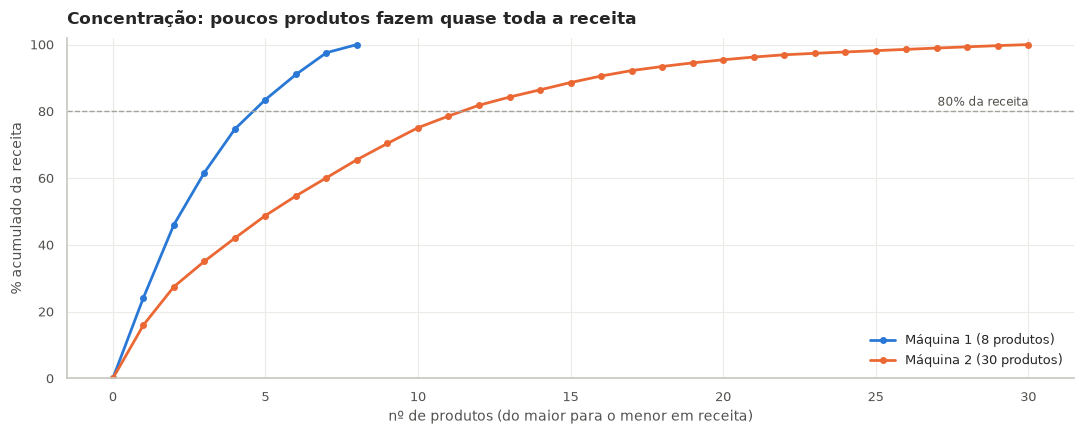

In [13]:
display(pa.resumo_concentracao_negocio(base).round(1))
display(pa.curva_pareto(base, "Máquina 2").round(1))
display(pa.familias_insumo(base).round(1))
mostrar(pa.grafico_pareto(base))

**Leitura:**
- **A receita está concentrada em poucos produtos:** no histórico total, **5 de 33 produtos fazem 80% da receita**, e os 8 produtos da M1 somam 97%. Os 3 maiores (Latte, Americano with milk e Cappuccino) fazem 60%.
- **A M2 tem uma cauda longa:** 30 produtos, dos quais **17 venderam no máximo 5 vezes em 44 dias** (menos de 1 por semana) e somam só 16% da receita. 12 produtos fazem 80%.
- **Insumos:** leite está em 66% das vendas da M1 e 47% da M2; é o insumo crítico. Na M2, a família baunilha tem 3 produtos e 6 vendas em 44 dias (2% da receita): cortar os 3 tira um insumo de linha. Já os produtos com aroma de whiskey fazem **32% da receita da M2** e não existem na M1; são o diferencial da M2, não cauda.
- **Limite da leitura:** sem custo e margem por produto, a cauda é candidata a revisão, não a corte automático. Um produto pouco vendido pode ter margem alta ou atrair um cliente que compra outros itens.

### 6.2 Ticket médio: preço, mix e público

Na M1, a última mudança de tabela é de 06/10/2024, antes da quebra de 30/01/2025. Entre essas datas e depois da quebra, **os preços são os mesmos**, então qualquer variação do ticket vem do **mix**, isto é, do que o público escolhe. A M2 entra como comparação no mesmo período.

In [14]:
tickets, mix_m1, resumo_ticket = pa.ticket_por_publico(base, quebras["Máquina 1"][-1])
display(tickets.round(1))
display(mix_m1.round(1))
display(pd.Series({k: v for k, v in resumo_ticket.items()}, dtype=object))

,início,fim,transações,ticket médio,% vendas a partir das 19h
grupo,,,,,
M1 · base anterior (mesma tabela),2024-10-06,2025-01-29,1075,32.500,21.000
M1 · desde a quebra (todos),2025-01-30,2025-03-23,763,31.300,9.400
"M1 · desde a quebra, cartões novos",2025-01-30,2025-03-23,689,31.500,9.400
"M1 · desde a quebra, cartões antigos",2025-01-30,2025-03-21,74,29.600,9.500
M2 · desde a abertura,2025-02-08,2025-03-23,262,26.300,17.900


,% antes,% depois,preço (u.m.),Δ p.p.
produto,,,,
Latte,24.900,14.800,35.800,-10.100
Cortado,8.600,1.800,26.000,-6.700
Hot chocolate,11.300,7.500,35.800,-3.900
Americano with milk,20.800,19.000,30.900,-1.800
Espresso,3.000,3.500,21.100,0.600
Cappuccino,11.900,12.800,35.800,0.900
Cocoa,9.100,11.400,35.800,2.300
Americano,10.300,29.100,26.000,18.800


última mudança de tabela da M1                                          2024-10-06 00:00:00
quebra                                                                  2025-01-30 00:00:00
ticket antes                                                                         32.451
ticket depois                                                                        31.277
variação do ticket da M1 (%)                                                         -3.616
ticket M2                                                                            26.298
M2 vs M1 no período comum (%)                                                       -15.607
desconto da M2 nos mesmos produtos (%)    {'Americano': -3.7, 'Americano with milk': -19...
% dinheiro na M2                                                                     30.534
dtype: object

**Leitura:**
- **O público mais recente gasta menos por compra.**
  - Na M1, o ticket cai de **32,5 para 31,3 u.m. (−3,6%) com a mesma tabela de preços**.
  - A nova clientela troca Latte e Cortado por **Americano**, o item mais barato depois do Espresso: o Americano sobe de 10% para **29%** das vendas.
- **A M2 tem ticket de 26,3 u.m., 16% abaixo da M1 no mesmo período.** Isso vem da tabela própria, mais barata nos mesmos produtos (Americano with milk −19%, Cappuccino −16%, Latte −8%), e de 31% de vendas em dinheiro.
- **O horário também mudou:** as vendas da M1 a partir das 19h caem de 21% para 9% com o novo público.
- **Implicação:** a receita cresce menos que o volume. Para recuperar ticket, há duas alavancas para testar: venda adicional sobre o Americano (por exemplo, a versão com leite) e uma revisão da tabela da M2. Não há como estimar elasticidade-preço com estes dados, então qualquer mudança de preço deve ser testada antes.

## Síntese da EDA

| Tema | Achado | Decisão para a modelagem |
|---|---|---|
| Granularidade | < 1 venda/hora | previsão **diária**; a hora vira atributo comportamental |
| Distribuição | contagens assimétricas, variância cresce com o nível | modelos de contagem (Poisson/NB2) e transformação de Anscombe |
| Máquinas | níveis, perfis semanais e tickets diferentes | um modelo por série; Total modelado diretamente |
| Ausentes | estruturais (dinheiro, coluna inexistente, máquina inexistente) | nenhuma imputação; clientes só na M1 |
| Zeros | 7 na M1, implausíveis como acaso (provável fechamento) | mantidos como zero; tema de monitoramento |
| Outliers | poucos, legítimos; impacto ≈ 0; 6 de 8 quedas em feriado ou fim de semana | nenhum removido; calendário de feriados e fechamentos em produção |
| Preços e ticket | duas mudanças de tabela em 2024; público de 2025 com ticket 3,6% menor (mix) e M2 16% abaixo | janelas recentes / ticket móvel na receita |
| Padrão semanal | só existe na M1 a partir de 2025 (fim de semana −55%) | reestimar o padrão no regime vigente (janelas curtas) |
| Duplicados | 2 exatos na M2, dentro de pedidos com vários itens; recompras da M1 levam ~1 min | nada removido: parecem 2 unidades na mesma compra, sem ID de pedido para confirmar |
| Produtos | 5 de 33 produtos = 80% da receita; 17 dos 30 da M2 com ≤ 5 vendas | previsão no nível da máquina; cauda da M2 é tema de negócio |
| Patamares | mudanças abruptas de nível | testar quebras (notebook 03) e criar dummies (notebook 04) |